# 실습02 · 사전학습 Backbone 입력 조건과 공식 transforms

> 원본 스크립트: `02_응용/02_transforms.py` (정답 주석본: `02_응용_주석/02_transforms.py`) · PPT 25쪽 · TODO A02

## 학습 목표
- 공식 ResNet18 가중치(`ResNet18_Weights.IMAGENET1K_V1`)가 요구하는 입력 변환을 `weights.transforms()`로 가져온다.
- 소형 source Backbone의 입력 조건([0,1], 32×32)과 ImageNet 입력 조건(Resize256→Crop224→Normalize)을 비교한다.
- 고정 Backbone과 새 Head가 각각 무엇을 학습하는지 파라미터 수로 확인한다.

## 핵심 개념

| 경로 | 크기 | 값 범위 | 출처 |
|---|---|---|---|
| 소형 source | (3, 32, 32) | [0, 1] | 합성 도형 source 240장으로 학습한 TinyShapeCNN |
| 공식 ResNet18 | (3, 224, 224) | Normalize 후 대략 -2 ~ 2.6 | ImageNet-1K |

주의: Weight Enum과 transforms 생성은 가중치를 내려받지 않는다.

In [1]:
# ============================================================
# 0. 노트북 실행 환경 준비
# ============================================================

# 파일·폴더 경로를 객체로 다루는 Path
from pathlib import Path
# 결과 목록을 JSON 파일로 저장
import json
# 수치 배열 계산과 source 가중치(npz) 읽기
import numpy as np
# 결과 표(DataFrame) 생성·CSV 저장
import pandas as pd
# PyTorch: Tensor 연산, 자동 미분, 난수 seed
import torch
# 신경망 층(Conv2d, Linear 등)과 손실 함수
from torch import nn
# data/분할/클래스 폴더 구조를 데이터셋으로 읽는 ImageFolder
from torchvision.datasets import ImageFolder
# 이미지 변환(Resize, ToTensor) 묶음
from torchvision import transforms as tr
# 분류 평가 지표: 정확도, F1, 클래스별 보고서, 혼동행렬
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
# Matplotlib: 노트북 안에 이미지·그래프 표시
import matplotlib.pyplot as plt
# 공식 ResNet18 가중치 정보(Enum)와 전용 transforms
from torchvision.models import ResNet18_Weights
# PNG 이미지를 PIL 형식으로 열기
from PIL import Image

# CPU 스레드 1개, seed 14 고정 -> .py 스크립트와 같은 재현 조건
torch.set_num_threads(1)
torch.manual_seed(14)

# 노트북은 자기 폴더(02_응용/)를 작업 경로로 실행된다
# - DATA : 원본 입력 (읽기만 하고 덮어쓰지 않음)
# - OUT  : 노트북이 만드는 결과물 전용 폴더 (스크립트의 outputs/와 분리)
DATA = Path("data")
OUT = Path("outputs_notebook")
OUT.mkdir(exist_ok=True)

# [0,1] RGB 32×32 -> 소형 source Backbone의 학습 입력 조건
# 주의: ImageNet Normalize는 넣지 않음
transform = tr.Compose([tr.Resize((32, 32)), tr.ToTensor()])
print("torch", torch.__version__, "/ 결과 폴더:", OUT)

torch 2.15.0+cu132 / 결과 폴더: outputs_notebook


## 1. TODO A02 · 공식 Weight의 transforms 가져오기

In [2]:
# ============================================================
# 1. TODO A02: weights.transforms()
# ============================================================

weights = ResNet18_Weights.IMAGENET1K_V1
official = weights.transforms()

# 변환 객체가 담고 있는 설정 확인
print(official)
print("resize_size:", official.resize_size, "/ crop_size:", official.crop_size)
print("mean:", official.mean, "/ std:", official.std)

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
resize_size: [256] / crop_size: [224]
mean: [0.485, 0.456, 0.406] / std: [0.229, 0.224, 0.225]


## 2. 같은 이미지에 두 변환 적용

In [3]:
# ============================================================
# 2. 같은 valid circle 이미지에 두 경로 적용
# ============================================================

image = Image.open(sorted((DATA / "valid" / "circle").glob("*.png"))[0]).convert("RGB")
small = transform(image)
big = official(image)
print("원본 PIL 크기:", image.size)
print("소형 source 입력:", tuple(small.shape), "범위 [0,1] ->", round(float(small.min()), 3), "~", round(float(small.max()), 3))
print("공식 ResNet 입력:", tuple(big.shape), "Normalize 후 범위 ->", round(float(big.min()), 3), "~", round(float(big.max()), 3))
print("작은 source와 ImageNet의 Normalize를 서로 섞지 않습니다.")

원본 PIL 크기: (40, 40)
소형 source 입력: (3, 32, 32) 범위 [0,1] -> 0.29 ~ 0.929
공식 ResNet 입력: (3, 224, 224) Normalize 후 범위 -> -1.005 ~ 2.113
작은 source와 ImageNet의 Normalize를 서로 섞지 않습니다.


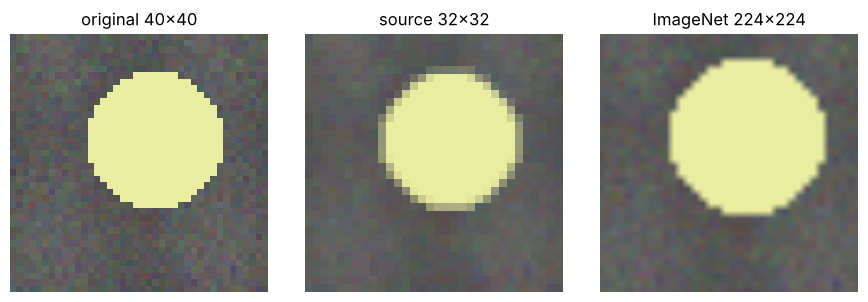

In [4]:
# 두 경로 결과를 보기 위해 [0,1]로 되돌려 표시 (공식 경로는 mean/std 역변환)
mean = torch.tensor(official.mean).view(3, 1, 1)
std = torch.tensor(official.std).view(3, 1, 1)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(image); axes[0].set_title("original 40x40")
axes[1].imshow(small.permute(1, 2, 0)); axes[1].set_title("source 32x32")
axes[2].imshow((big * std + mean).clamp(0, 1).permute(1, 2, 0)); axes[2].set_title("ImageNet 224x224")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT / "p02_transform_compare.png", dpi=100)
plt.show()

## 3. 고정 Backbone과 새 Head의 파라미터 수

In [5]:
# ============================================================
# 3. TinyShapeCNN: Backbone(0~8)과 새 Head(9) 파라미터 수
# ============================================================

torch.manual_seed(14)
model = nn.Sequential(
    nn.Conv2d(3, 8, 3, padding=1, bias=False), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(8, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(),
    nn.AdaptiveAvgPool2d((4, 4)), nn.Flatten(), nn.Linear(256, 3),
)
with np.load(DATA / "source_backbone.npz", allow_pickle=False) as saved:
    print("npz 배열:", saved.files)

backbone = sum(p.numel() for p in model[:9].parameters())
head = sum(p.numel() for p in model[9].parameters())
print("Backbone 파라미터:", backbone, "/ 새 Head 파라미터:", head)
print("source_provenance:", json.loads((DATA / "source_provenance.json").read_text(encoding="utf-8"))["kind"])

npz 배열: ['0.weight', '1.weight', '1.bias', '1.running_mean', '1.running_var', '1.num_batches_tracked', '4.weight', '5.weight', '5.bias', '5.running_mean', '5.running_var', '5.num_batches_tracked']
Backbone 파라미터: 1416 / 새 Head 파라미터: 771
source_provenance: synthetic_source_pretraining


## 정리 · README 정답 예와 대조

README 정답 실행 예: `(3, 32, 32)`, `(3, 224, 224)`, `[256] [224]`, mean/std `[0.485, 0.456, 0.406] [0.229, 0.224, 0.225]`.

- **고정 Backbone과 새 Head:** Backbone(Conv·BN, 파라미터 1,416개)은 source에서 배운 경계·모양 특징을 그대로 제공하고, 새 Head(Linear 256→3, 771개)는 그 256차원 특징을 Target 클래스 3개의 점수로 바꾸는 규칙만 학습한다.
- **출처가 같은가?** 같지 않다. 공식 ResNet18은 ImageNet 실사 사진, 소형 source는 이 수업용 합성 도형 240장(`source_provenance.json`, `imagenet: false`)에서 학습했다. 그래서 입력 크기·Normalize도 서로 다르다.